In [1]:
import numpy as np

def plot_bin_matrix_heatmap(matrix_file_path, bin_length):
    with open(matrix_file_path, 'r') as f:
        matrix = [list(map(float, line.strip().split())) for line in f if line.strip()]
    
    matrix = np.array(matrix)
    num_bins_y, num_bins_x = matrix.shape
    
    fig, ax = plt.subplots(figsize=(8, 8))
    heatmap = ax.imshow(matrix, cmap='viridis', origin='lower', extent=[0, num_bins_x * bin_length, 0, num_bins_y * bin_length])

    # Add numbers to each bin
    for i in range(num_bins_y):
        for j in range(num_bins_x):
            x = (j + 0.5) * bin_length
            y = (i + 0.5) * bin_length
            value = matrix[i, j]
            ax.text(x, y, f'{value:.1f}', ha='center', va='center', color='white' if value > np.max(matrix)/2 else 'black', fontsize=10)

    ax.set_xticks(np.arange(0, num_bins_x * bin_length + 1, bin_length))
    ax.set_yticks(np.arange(0, num_bins_y * bin_length + 1, bin_length))
    ax.grid(True, which='both', color='gray', linestyle='--', linewidth=0.5)
    ax.set_title("Bin Matrix Heatmap")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")

    plt.colorbar(heatmap, ax=ax, label='Value')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()

In [2]:
import matplotlib.pyplot as plt
import networkx as nx
import math

def parse_and_plot_graph(file_path, show_slots=False):
    with open(file_path+".txt", 'r') as f:
        lines = [line.strip() for line in f if line.strip()]
    
    # Parse metadata
    header = lines[0].split()
    number_of_binsx = int(header[0])
    number_of_binsy = int(header[1])
    number_of_slots_per_bin = int(math.sqrt(int(header[2])))
    bin_length = float(header[3])
    
    # Parse inputs and outputs
    inputs = list(map(int, lines[1].split()[:]))
    print(inputs)
    outputs = list(map(int, lines[2].split()[:]))
    print(outputs)

    # Parse node data
    nodes = {}
    radii = {}
    edges = []
    for line in lines[3:]:
        parts = line.split()
        node = int(parts[0])
        radius = float(parts[1])
        x, y = float(parts[2]), float(parts[3])
        children = list(map(int, parts[4:]))
        nodes[node] = (x, y)
        radii[node] = radius
        for child in children:
            edges.append((child, node))  # directed from child to current node

    # Create graph
    G = nx.DiGraph()
    for node, pos in nodes.items():
        G.add_node(node, pos=pos)
    G.add_edges_from(edges)

    # Plotting
    plt.figure(figsize=(10, 10))
    pos = nx.get_node_attributes(G, 'pos')

    # Draw edges
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15)

    # Draw nodes manually as circles with radii
    ax = plt.gca()
    for node, (x, y) in nodes.items():
        radius = radii[node]
        color = 'skyblue'
        if node in inputs:
            color = 'lightgreen'
        elif node in outputs:
            color = 'salmon'
        circle = plt.Circle((x, y), radius, color=color, alpha=0.6, ec='black')
        ax.add_patch(circle)
        plt.text(x, y, str(node), fontsize=8, ha='center', va='center')

    # Draw bin and slot grid
    max_coordx = ( number_of_binsx ) * bin_length
    max_coordy = ( number_of_binsy ) * bin_length
    for i in range(number_of_binsx + 1):
        x = i * bin_length
        plt.plot([x, x], [0, max_coordy], 'k--', linewidth=0.5)

        if show_slots:
            slot_size = bin_length / number_of_slots_per_bin
            for j in range(1, number_of_slots_per_bin):
                x_inner = i * bin_length + j * slot_size
                if x_inner < max_coordx:
                    plt.plot([x_inner, x_inner], [0, max_coordy], 'k:', linewidth=0.3)

    for i in range(number_of_binsy + 1):
        y = i * bin_length
        plt.plot([0, max_coordx], [y, y], 'k--', linewidth=0.5)

        if show_slots:
            slot_size = bin_length / number_of_slots_per_bin
            for j in range(1, number_of_slots_per_bin):
                y_inner = i * bin_length + j * slot_size
                if y_inner < max_coordy:
                    plt.plot([0, max_coordx], [y_inner, y_inner], 'k:', linewidth=0.3)

    plt.xlim(-1, max_coordx + 1)
    plt.ylim(-1, max_coordy + 1)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.title("Graph Visualization with Node Radii")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.show()

    #plot_bin_matrix_heatmap( file_path + "_matrix.txt", bin_length )
    

- Disk symmetry simplifies geometry and avoids biasing toward axes (as in rectangular grids).

- I/O fixed on perimeter models realistic boundary pin constraints.

- Spreading constraint enforces realistic density without overlap, reflecting placement feasibility.

- Delay proxy based on wirelength² gives a good approximation to post-routing interconnect delay in absence of parasitic extraction.

- Early feedback loop: You can optimize logic or mapping decisions using this geometric proxy before layout.

[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]
[53, 101, 152, 197, 198, 202, 207]


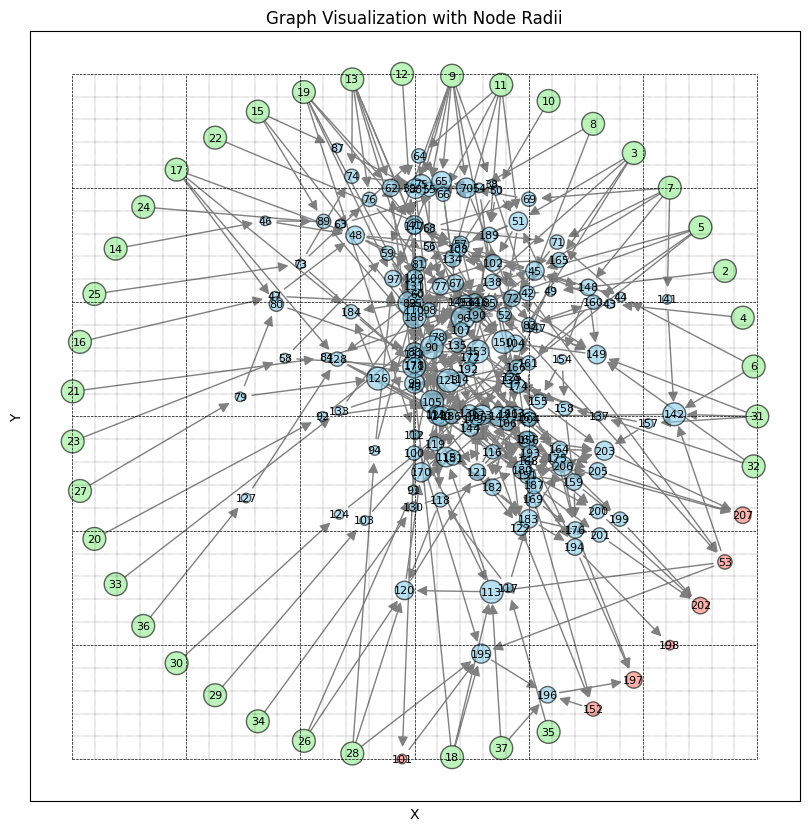

In [3]:
parse_and_plot_graph( "c432_opto_0", True )

[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]
[53, 101, 215, 197, 198, 237, 207]


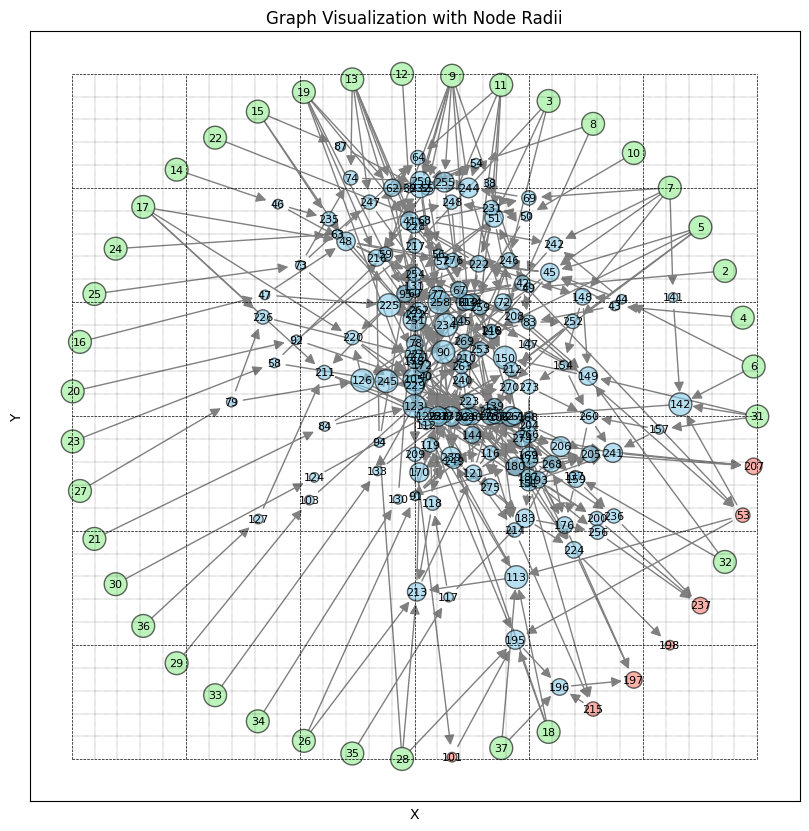

In [4]:
parse_and_plot_graph( "c432_opto_1", True )

[2, 3, 4, 5]
[8]


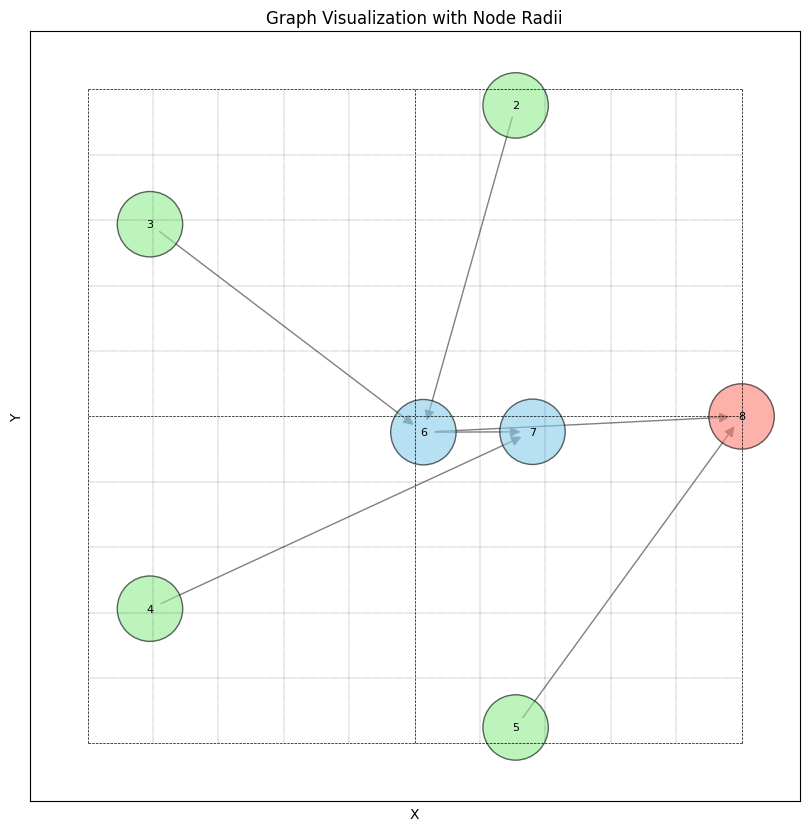

In [9]:
parse_and_plot_graph( "test1_bef", True )

[2, 3, 4, 5]
[8]


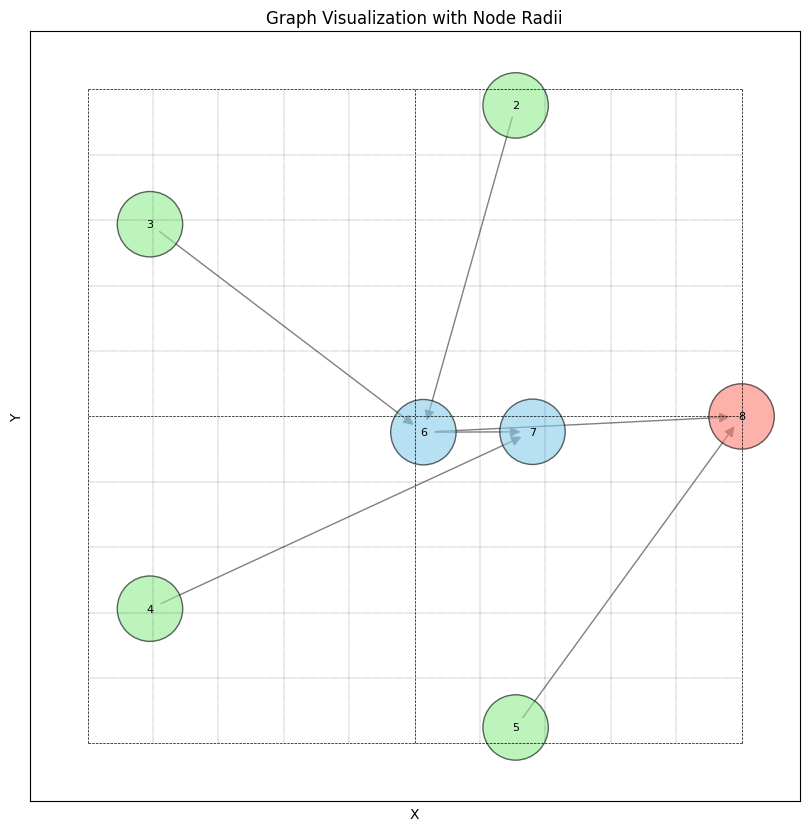

In [10]:
parse_and_plot_graph( "test1_aft", True )

In [28]:
import re

# Your multiline string
table = """
c432 &$    131776.98 $&$   129621.56 $&$  1358.04 $&$  1351.24 $&$   0.90 $&$  326.09 $&$   325.33 $&$   6.83  $&$   6.53  $&$ 21    $&$     21 $&$  381.1  $&$  359.8  $\\
c499 &$   1510932.50 $&$  1455445.88 $&$  7998.20 $&$  7905.19 $&$   8.24 $&$  332.64 $&$   317.49 $&$  39.70  $&$  40.90  $&$ 68    $&$     65 $&$  1357.3 $&$  1283.7 $\\
c880 &$   1269599.75 $&$  1245127.50 $&$  4932.42 $&$  4891.15 $&$   2.14 $&$  224.51 $&$   226.89 $&$   9.92  $&$  10.20  $&$ 35    $&$     35 $&$   704.5 $&$  819.4  $\\
c1355 &$   1632449.12 $&$  1582149.38 $&$  8283.94 $&$  7919.78 $&$  11.78 $&$  313.04 $&$   318.27 $&$  41.60  $&$  43.50  $&$ 71    $&$     68 $&$  1449.1 $&$  1405.2 $\\
c1908 &$    635776.19 $&$   557880.94 $&$  3732.05 $&$  3593.00 $&$   1.71 $&$  302.31 $&$   323.41 $&$  14.40  $&$  14.50  $&$ 39    $&$     38 $&$   683.6 $&$   667.9 $\\
c2670 &$   8262358.50 $&$  7579281.50 $&$ 15102.50 $&$ 14203.16 $&$  61.27 $&$  244.91 $&$   238.67 $&$  22.10  $&$  22.00  $&$ 66    $&$     65 $&$  1482.5 $&$  1513.2 $\\
c3540 &$   2416894.00 $&$  2341708.50 $&$ 10953.60 $&$ 10781.18 $&$  11.05 $&$  462.69 $&$   468.81 $&$  45.70  $&$  45.20  $&$ 85    $&$     83 $&$  1859.5 $&$  1822.8 $\\
c5315 &$  89444224.00 $&$ 71216384.00 $&$ 50519.52 $&$ 45698.35 $&$ 114.40 $&$  330.48 $&$   319.07 $&$  45.90  $&$  44.60  $&$117    $&$    115 $&$  2963.7 $&$  2831.7 $\\
c6288 &$  22131452.00 $&$ 20767166.00 $&$ 49934.18 $&$ 49116.47 $&$ 216.68 $&$  919.11 $&$   907.31 $&$  54.00  $&$  55.60  $&$370    $&$    368 $&$  5959.8 $&$  5837.7 $\\
c7552 &$  46120648.00 $&$ 38581756.00 $&$ 51800.49 $&$ 46308.06 $&$ 155.56 $&$  580.54 $&$   560.19 $&$  68.20  $&$  34.60  $&$147    $&$    146 $&$  3115.4 $&$  2854.0 $\\
"""

import re

# Parse table into rows
rows = []
for line in table.strip().splitlines():
    clean = re.sub(r'[\\$]', '', line)
    items = [x.strip() for x in clean.split('&')]
    # Convert non-name entries to float
    row = [items[0]] + [float(x) for x in items[1:]]
    rows.append(row)

# Transpose to columns
columns = list(map(list, zip(*rows)))

# Print columns for confirmation (optional)
# for i, col in enumerate(columns):
#     print(f"column_{i} = {col}")

# Define index pairs for computing variations
paired_indices = [(1, 2), (3, 4), (6, 7), (8, 9), (10, 11), (12, 13)]

print("Average relative differences (as percentages):")
for left, right in paired_indices:
    left_col = columns[left]
    right_col = columns[right]
    avg_rel_diff = sum((r - l) / l for l, r in zip(left_col, right_col)) / len(left_col)
    print(f"Columns {left} & {right}: {avg_rel_diff*100:.2f}%")

np.mean( columns[5] )

Average relative differences (as percentages):
Columns 1 & 2: -7.68%
Columns 3 & 4: -3.99%
Columns 6 & 7: -0.45%
Columns 8 & 9: -4.40%
Columns 10 & 11: -1.80%
Columns 12 & 13: -1.48%


58.373000000000005